In [1]:
import sys

sys.path.append("../src")
from pipeline import data_preparation_pipeline
from functions import create_temp_strat_bin
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/whoop_fitness_dataset_100k.csv")


function.py imported successfully
pipeline.py imported successfully


In [2]:
df = create_temp_strat_bin(df)

x = df.drop(columns=["recovery_score", "score_bins"])
y = df["recovery_score"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=df["score_bins"]
)

df.drop(columns=["score_bins"], inplace=True, errors="ignore")

x_train_processed = data_preparation_pipeline.fit_transform(x_train, y_train)
x_test_processed = data_preparation_pipeline.transform(x_test)

In [3]:
x_train_processed.columns

Index(['gender_Female', 'activity_type_CrossFit', 'activity_type_Cycling',
       'activity_type_Weight Training', 'fitness_level', 'age', 'weight_kg',
       'height_cm', 'day_strain', 'sleep_hours', 'sleep_efficiency',
       'light_sleep_hours', 'hrv', 'resting_heart_rate', 'hrv_baseline',
       'rhr_baseline', 'calories_burned', 'activity_duration_min',
       'activity_strain', 'activity_calories', 'hr_zone_1_min',
       'hr_zone_5_min', 'hrv_ratio', 'rhr_ratio', 'bmi'],
      dtype='str')

In [4]:
from sklearn.tree import DecisionTreeRegressor

dtr = DecisionTreeRegressor( random_state=42 )

dtr.fit(x_train_processed, y_train)

predict_dtr = dtr.predict(x_test_processed)



In [5]:
from sklearn.ensemble import RandomForestRegressor

rtr = RandomForestRegressor( random_state=42 )

rtr.fit(x_train_processed, y_train)

predict_rtr = rtr.predict(x_test_processed)

In [6]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor( random_state=42 )

gbr.fit(x_train_processed, y_train)

predict_gbr = gbr.predict(x_test_processed)

In [7]:
from xgboost import XGBRegressor

xgbr = XGBRegressor( random_state=42 )

xgbr.fit(x_train_processed, y_train)

predict_xgbr = xgbr.predict(x_test_processed)

In [8]:
from lightgbm import LGBMRegressor

lgbm = LGBMRegressor( random_state=42 )

lgbm.fit(x_train_processed, y_train)

predict_lgbm = lgbm.predict(x_test_processed)

In [9]:
from sklearn.metrics import (

    root_mean_squared_error, 
    mean_squared_error, 
    mean_absolute_error,
    mean_absolute_percentage_error,
    max_error,
    r2_score
)

models = {
    "Decision Tree Regressor": predict_dtr,
    "Random Forest Regressor": predict_rtr,
    "Gradient Boosting Regressor": predict_gbr,
    "XGBoost Regressor": predict_xgbr,
    "LGBM Regressor": predict_lgbm
}

evaluation_results = []

for model_name, prediction in models.items():
    rmse = root_mean_squared_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    mae = mean_absolute_error(y_test, prediction)
    mape = mean_absolute_percentage_error(y_test, prediction)
    me = max_error(y_test, prediction)
    r2 = r2_score(y_test, prediction)
    
    evaluation_results.append([
        model_name,
        rmse,
        mse,
        mae,
        mape,
        me,
        r2
    ])
    
evaluation_table = pd.DataFrame(
    evaluation_results,
    columns=[
        "Model",
        "RMSE",
        "MSE",
        "MAE",
        "MAPE",
        "ME",
        "R² Score"
    ]
)

evaluation_table


,Model,RMSE,MSE,MAE,MAPE,ME,R² Score
0,Decision Tree Regressor,19.682134,387.386412,15.687380,0.267154,72.900000,-0.236388
1,Random Forest Regressor,13.654726,186.451547,10.993214,0.191634,55.991000,0.404919
2,Gradient Boosting Regressor,13.597753,184.898886,10.967775,0.192274,50.703071,0.409874
3,XGBoost Regressor,12.793204,163.666063,10.241267,0.177548,54.732874,0.477641
4,LGBM Regressor,12.695028,161.163744,10.187188,0.177259,54.840908,0.485627


In [10]:
from scipy.stats import randint, uniform

param_dtr = {
    "max_depth": randint(5, 10),
    "min_samples_leaf": randint(10, 20)
}

param_rtr = {
    "n_estimators": randint(50, 200),
    "max_depth": randint(5, 15),
    "min_samples_leaf": randint(5, 20)
}

param_gbr = {
    "n_estimators": randint(100, 300),
    "max_depth": randint(2, 8),
    "min_samples_leaf": randint(5, 15),
    "learning_rate": uniform(0.05, 0.05),
    "subsample": uniform(0.85, 0.15)
}

param_xgbr = {
    "n_estimators": randint(100, 300),
    "max_depth": randint(2, 8),
    "learning_rate": uniform(0.01, 0.19),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.6, 0.4)
}

param_lgbm = {
    "n_estimators": randint(100, 300),
    "num_leaves": randint(15, 60),
    "learning_rate": uniform(0.01, 0.2),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.6, 0.4)
}

In [11]:
from sklearn.model_selection import KFold, RandomizedSearchCV

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models_and_params = {
    "Decision Tree Regressor": (DecisionTreeRegressor(random_state=42), param_dtr),
    "Random Forest Regressor": (RandomForestRegressor(random_state=42), param_rtr),
    "Gradient Boosting Regressor": (GradientBoostingRegressor(random_state=42), param_gbr),
    "XGBoost Regressor": (XGBRegressor(random_state=42), param_xgbr),
    "LGBM Regressor": (LGBMRegressor(random_state=42, verbose=-1), param_lgbm),
}

best_model_params = []

for name, (model, params) in models_and_params.items():
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter= 10 if (name == "Random Forest Regressor" or name == "Gradient Boosting Regressor") else 30,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        random_state=42,
        verbose=1
    )
    search.fit(x_train_processed, y_train)
    
    best_model_params.append(
        {"model_name": name, "best_params": search.best_params_}
    )

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [12]:
dtr_tuned_params = best_model_params[0]["best_params"]
rtr_tuned_params = best_model_params[1]["best_params"]
gbr_tuned_params = best_model_params[2]["best_params"]
xgbr_tuned_params = best_model_params[3]["best_params"]
lgbm_tuned_params = best_model_params[4]["best_params"]

In [13]:
dtr_hypertuned = DecisionTreeRegressor(**dtr_tuned_params, random_state=42)

dtr_hypertuned.fit(x_train_processed, y_train)

predict_dtr_hypertuned = dtr_hypertuned.predict(x_test_processed)

In [14]:
rtr_hypertuned = RandomForestRegressor(**rtr_tuned_params, random_state=42)

rtr_hypertuned.fit(x_train_processed, y_train)

predict_rtr_hypertuned = rtr_hypertuned.predict(x_test_processed)

In [15]:
gbr_hypertuned = GradientBoostingRegressor(**gbr_tuned_params, random_state=42)

gbr_hypertuned.fit(x_train_processed, y_train)

predict_gbr_hypertuned = gbr_hypertuned.predict(x_test_processed)

In [16]:
xgbr_hypertuned = XGBRegressor(**xgbr_tuned_params, random_state=42)

xgbr_hypertuned.fit(x_train_processed, y_train)

predict_xgbr_hypertuned = xgbr_hypertuned.predict(x_test_processed)

In [17]:
lgbm_hypertuned = LGBMRegressor(**lgbm_tuned_params, random_state=42)

lgbm_hypertuned.fit(x_train_processed, y_train)

predict_lgbm_hypertuned = lgbm_hypertuned.predict(x_test_processed)

In [18]:
from sklearn.metrics import (

    root_mean_squared_error, 
    mean_squared_error, 
    mean_absolute_error,
    mean_absolute_percentage_error,
    max_error,
    r2_score
)

models = {
    "Decision Tree Regressor": predict_dtr_hypertuned,
    "Random Forest Regressor": predict_rtr_hypertuned,
    "Gradient Boosting Regressor": predict_gbr_hypertuned,
    "XGBoost Regressor": predict_xgbr_hypertuned,
    "LGBM Regressor": predict_lgbm_hypertuned
}

evaluation_results = []

for model_name, prediction in models.items():
    rmse = root_mean_squared_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    mae = mean_absolute_error(y_test, prediction)
    mape = mean_absolute_percentage_error(y_test, prediction)
    me = max_error(y_test, prediction)
    r2 = r2_score(y_test, prediction)
    
    evaluation_results.append([
        model_name,
        rmse,
        mse,
        mae,
        mape,
        me,
        r2
    ])
    
evaluation_table = pd.DataFrame(
    evaluation_results,
    columns=[
        "Hypertuned Model",
        "RMSE",
        "MSE",
        "MAE",
        "MAPE",
        "ME",
        "R² Score"
    ]
)

evaluation_table


,Hypertuned Model,RMSE,MSE,MAE,MAPE,ME,R² Score
0,Decision Tree Regressor,14.423780,208.045440,11.616759,0.202860,52.476527,0.335999
1,Random Forest Regressor,13.712162,188.023388,11.042797,0.192622,54.366927,0.399902
2,Gradient Boosting Regressor,12.624654,159.381894,10.118444,0.175816,52.171929,0.491314
3,XGBoost Regressor,12.644136,159.874166,10.139290,0.176382,52.697310,0.489743
4,LGBM Regressor,12.648503,159.984626,10.133181,0.176096,56.369219,0.489391


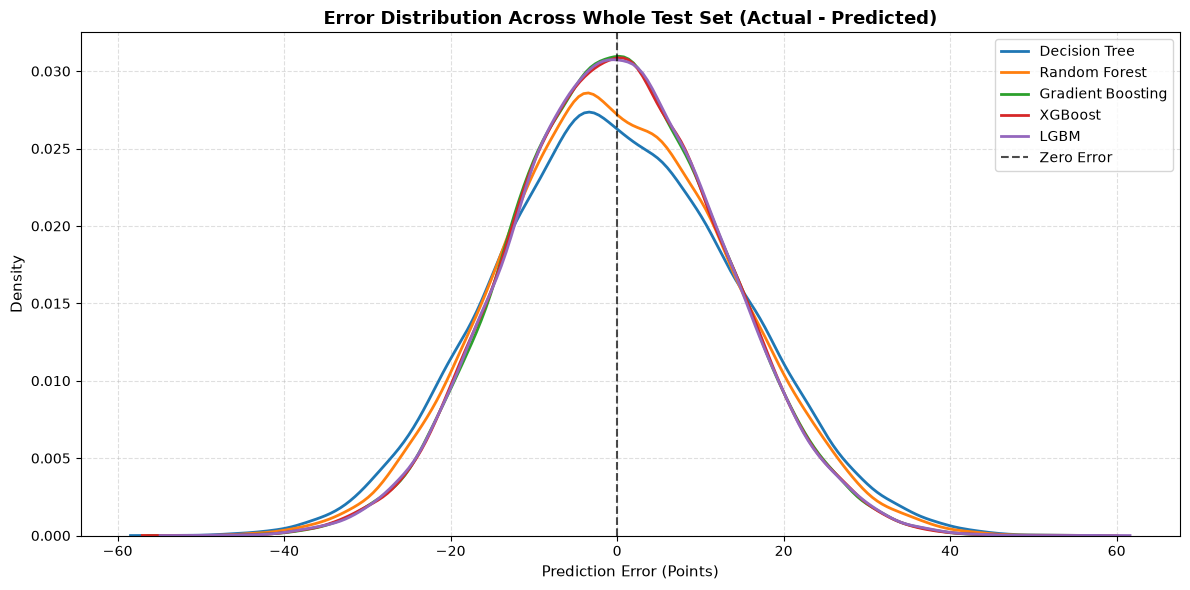

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate residuals (errors) across the entire test set
residuals_df = pd.DataFrame(
    {
        "Decision Tree": (
            y_test.values if hasattr(y_test, "values") else y_test
        )
        - predict_dtr_hypertuned,
        "Random Forest": (
            y_test.values if hasattr(y_test, "values") else y_test
        )
        - predict_rtr_hypertuned,
        "Gradient Boosting": (
            y_test.values if hasattr(y_test, "values") else y_test
        )
        - predict_gbr_hypertuned,
        "XGBoost": (y_test.values if hasattr(y_test, "values") else y_test)
        - predict_xgbr_hypertuned,
        "LGBM": (y_test.values if hasattr(y_test, "values") else y_test)
        - predict_lgbm_hypertuned,
    }
)

plt.figure(figsize=(12, 6))

for col in residuals_df.columns:
    sns.kdeplot(residuals_df[col], label=col, linewidth=2)

plt.axvline(0, color="black", linestyle="--", alpha=0.7, label="Zero Error")
plt.title(
    "Error Distribution Across Whole Test Set (Actual - Predicted)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Prediction Error (Points)", fontsize=11)
plt.ylabel("Density", fontsize=11)
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()